# Phase 3.1 — Visualizar meta-máscara `lfw_K4_q`

Espelho do notebook da Fase 3, para a máscara treinada **com qualidade** (SSIM hinge + L∞).

1. Carrega a **última** máscara `lfw_K4_q` (`LATEST_phase3_1_lfw_K4_q.txt`).
2. Visualiza a máscara **sozinha** (magnitude DT-CWT L2/L3 + residual espacial).
3. Aplica em **3 faces** LFW com o bound L∞ do treino e mostra antes / depois.
4. Mede **distância de cosseno** (FR) e **SSIM** (qualidade).
5. Avalia um conjunto maior (~200 faces de teste) e reporta médias / percentis.

In [7]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pytorch_msssim import ssim as calc_ssim

REPO_ROOT = Path("..").resolve()
PROTEGO_BASE = REPO_ROOT / "protego_base"
if str(PROTEGO_BASE) not in sys.path:
    sys.path.insert(0, str(PROTEGO_BASE))

from protego.FacialRecognition import FR
from protego.datasets import list_image_paths, resolve_split_dir
from protego.dtcwt_mask import DTCWTMetaMaskModule
from protego.quality_loss import apply_linf_budget
from protego.utils import load_imgs

MASK_ROOT = Path("/mnt/study-data/dcarvalho/tests")
LATEST_PTR = MASK_ROOT / "LATEST_phase3_1_lfw_K4_q.txt"
N_IMAGES = 3
N_EVAL = 200  # batch evaluation size (section 5)
EVAL_BATCH = 16
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)
print("latest pointer:", LATEST_PTR)
print("N_EVAL:", N_EVAL, "| EVAL_BATCH:", EVAL_BATCH)

device: cuda:0
latest pointer: /mnt/study-data/dcarvalho/tests/LATEST_phase3_1_lfw_K4_q.txt
N_EVAL: 200 | EVAL_BATCH: 16


## 1. Carregar checkpoint `lfw_K4_q`

In [8]:
assert LATEST_PTR.is_file(), f"Pointer not found: {LATEST_PTR}"
mask_path = Path(LATEST_PTR.read_text(encoding="utf-8").strip())
assert mask_path.is_file(), f"Mask missing: {mask_path}"

ckpt = torch.load(mask_path, map_location="cpu", weights_only=False)
cfg = ckpt.get("config", {})
img_size = int(ckpt.get("img_size", cfg.get("img_size", 224)))
fr_name = cfg.get("fr_model", "inception_facenet_vgg")
epsilon = float(cfg.get("epsilon", 16 / 255))
min_ssim = float(cfg.get("min_ssim", 0.95))

print("run_id     :", cfg.get("run_id"))
print("phase      :", cfg.get("phase"))
print("mask_path  :", mask_path)
print("fr_model   :", fr_name)
print("quality    :", cfg.get("quality"), "| epsilon=", epsilon, "| min_ssim=", min_ssim)
print("final_loss :", ckpt.get("final_loss"))
print("img_size   :", img_size)

for k, v in ckpt["meta_mask"].items():
    print(f"  {k}: shape={tuple(v.shape)}  |mean|={v.abs().mean():.4f}  max|={v.abs().max():.4f}")

mask_mod = DTCWTMetaMaskModule(channels=3, img_size=img_size, J=3, editable_levels=(2, 3))
mask_mod.load_meta_mask_state(ckpt["meta_mask"])
mask_mod = mask_mod.to(DEVICE).eval()
for p in mask_mod.parameters():
    p.requires_grad_(False)

run_id     : 20261012_212432_phase3_1_lfw_K4_q
phase      : phase3_1
mask_path  : /mnt/study-data/dcarvalho/tests/20261012_212432_phase3_1_lfw_K4_q/meta_mask.pt
fr_model   : inception_facenet_vgg
quality    : True | epsilon= 0.06274509803921569 | min_ssim= 0.95
final_loss : 44.460445404052734
img_size   : 224
  delta_mag_2: shape=(1, 3, 6, 56, 56)  |mean|=0.0455  max|=1.0981
  delta_phase_2: shape=(1, 3, 6, 56, 56)  |mean|=0.5284  max|=2.6494
  delta_mag_3: shape=(1, 3, 6, 28, 28)  |mean|=0.0648  max|=1.4259
  delta_phase_3: shape=(1, 3, 6, 28, 28)  |mean|=0.3991  max|=2.5473


## 2. Máscara sozinha (sem face)

- **Magnitude de ΔW** nos níveis 2 e 3 (média RGB, 6 orientações).
- **Residual espacial** em cinza médio, **com e sem** bound L∞ (como no treino 3.1).

/tmp/ipykernel_3475786/3247271852.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


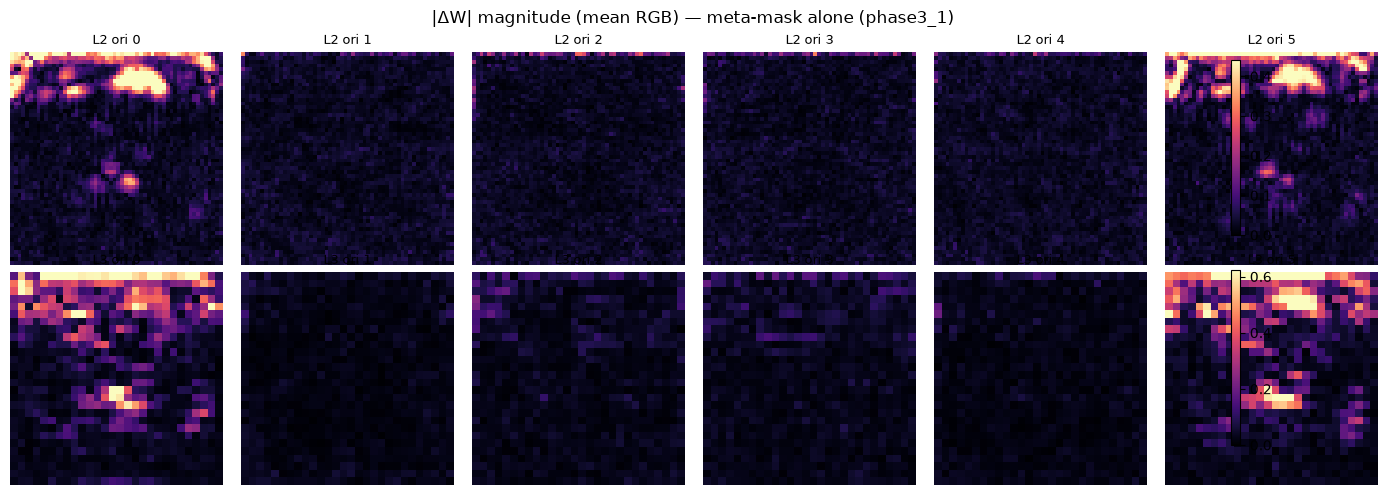

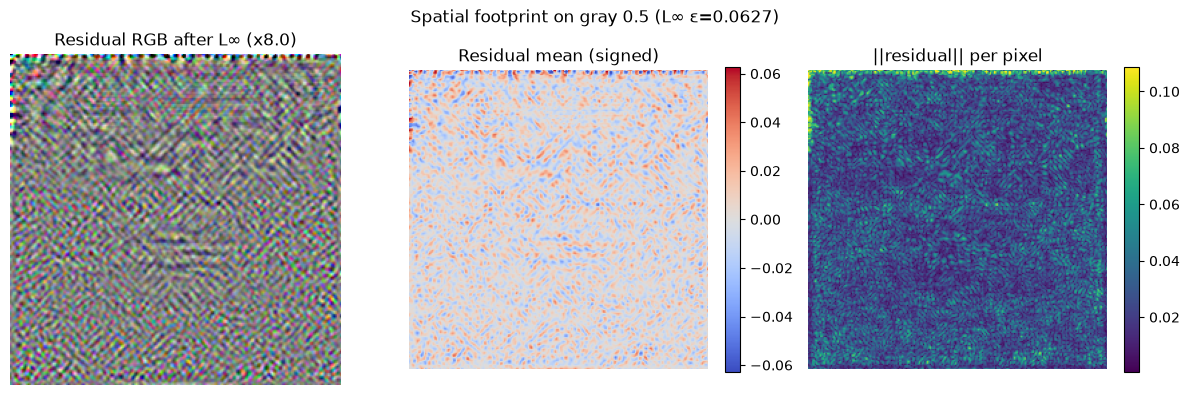

residual (after L∞): mean=-0.00001  std=0.01852  linf=0.06275  (budget=0.06275)


In [9]:
@torch.no_grad()
def show_mask_alone(module: DTCWTMetaMaskModule, epsilon: float, img_size: int = 224):
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for row, level in enumerate((2, 3)):
        mag = module.delta_mag[str(level)][0].detach().cpu().abs().mean(dim=0).numpy()
        vmax = np.percentile(mag, 99) + 1e-8
        for o in range(6):
            ax = axes[row, o]
            im = ax.imshow(mag[o], cmap="magma", vmin=0, vmax=vmax)
            ax.set_title(f"L{level} ori {o}", fontsize=9)
            ax.axis("off")
        fig.colorbar(im, ax=axes[row, :].tolist(), fraction=0.02, pad=0.02)
    fig.suptitle("|ΔW| magnitude (mean RGB) — meta-mask alone (phase3_1)", fontsize=12)
    plt.tight_layout()
    plt.show()

    gray = torch.full((1, 3, img_size, img_size), 0.5, device=DEVICE)
    recon = module(gray)  # no clamp yet
    prot, residual = apply_linf_budget(recon, gray, epsilon)
    residual = residual[0].detach().cpu()
    res_rgb = residual.permute(1, 2, 0).numpy()
    amp = min(10.0, 0.5 / (residual.abs().max().item() + 1e-8))

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(np.clip(res_rgb * amp + 0.5, 0, 1))
    axes[0].set_title(f"Residual RGB after L∞ (x{amp:.1f})")
    axes[0].axis("off")

    res_mean = residual.mean(dim=0).numpy()
    lim = max(res_mean.std() * 3, epsilon)
    im1 = axes[1].imshow(res_mean, cmap="coolwarm", vmin=-lim, vmax=lim)
    axes[1].set_title("Residual mean (signed)")
    axes[1].axis("off")
    fig.colorbar(im1, ax=axes[1], fraction=0.046)

    mag_map = residual.norm(dim=0).numpy()
    im2 = axes[2].imshow(mag_map, cmap="viridis")
    axes[2].set_title("||residual|| per pixel")
    axes[2].axis("off")
    fig.colorbar(im2, ax=axes[2], fraction=0.046)

    fig.suptitle(f"Spatial footprint on gray 0.5 (L∞ ε={epsilon:.4f})")
    plt.tight_layout()
    plt.show()

    print(
        f"residual (after L∞): mean={residual.mean():.5f}  std={residual.std():.5f}  "
        f"linf={residual.abs().max():.5f}  (budget={epsilon:.5f})"
    )

show_mask_alone(mask_mod, epsilon=epsilon, img_size=img_size)

## 3. Antes / depois em 3 imagens + cosseno + SSIM

Aplicação alinhada ao treino 3.1:

$$
X_{\mathrm{prot}} = X + \mathrm{clamp}(\hat{X}-X, -\varepsilon, \varepsilon)
$$

Métrica de desidentificação: **`cos_similarity`** (menor = melhor). SSIM comparado ao original.

In [10]:
fr = FR(model_name=fr_name, device=DEVICE)
fr.fr_model.model.eval()
for p in fr.fr_model.model.parameters():
    p.requires_grad_(False)

split_dir = resolve_split_dir("lfw_frontal", "test")
all_paths = list_image_paths(split_dir)
idxs = np.linspace(0, len(all_paths) - 1, num=N_IMAGES, dtype=int)
paths = [all_paths[i] for i in idxs]
print("images:")
for p in paths:
    print(" -", p)

imgs = load_imgs(img_paths=paths, img_sz=img_size, drange=1, device=DEVICE)

with torch.no_grad():
    recon = mask_mod(imgs)  # raw IDT-CWT
    protected, residual = apply_linf_budget(recon, imgs, epsilon)
    feat_orig = F.normalize(fr(imgs), p=2, dim=1)
    feat_prot = F.normalize(fr(protected), p=2, dim=1)
    cos_sim = (feat_orig * feat_prot).sum(dim=1)
    cos_dist = 1.0 - cos_sim
    # per-image SSIM
    ssims = []
    for i in range(N_IMAGES):
        s = calc_ssim(
            protected[i : i + 1], imgs[i : i + 1], data_range=1.0, size_average=True
        )
        ssims.append(float(s.cpu()))
    ssims = np.array(ssims)

print("\nMetrics (original vs protected, with L∞ budget):")
print("(cos_similarity: lower = better de-identification)")
for i, p in enumerate(paths):
    print(
        f"  [{i}] {Path(p).name}:  cos_similarity={cos_sim[i].item():.4f}  "
        f"SSIM={ssims[i]:.4f}  linf={residual[i].abs().max().item():.4f}"
    )
print(
    f"  mean cos_similarity={cos_sim.mean().item():.4f}  mean SSIM={ssims.mean():.4f}  "
    f"(target min_ssim={min_ssim})"
)

images:
 - /mnt/databases/faces/lfw_frontal/faces_test/img_000000.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_006572.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_013231.jpg

Metrics (original vs protected, with L∞ budget):
  [0] img_000000.jpg:  d_cos=0.0271  sim=0.9729  SSIM=0.8552  linf=0.0627
  [1] img_006572.jpg:  d_cos=0.0332  sim=0.9668  SSIM=0.8390  linf=0.0627
  [2] img_013231.jpg:  d_cos=0.0740  sim=0.9260  SSIM=0.8493  linf=0.0627
  mean d_cos=0.0448  mean SSIM=0.8478  (target min_ssim=0.95)


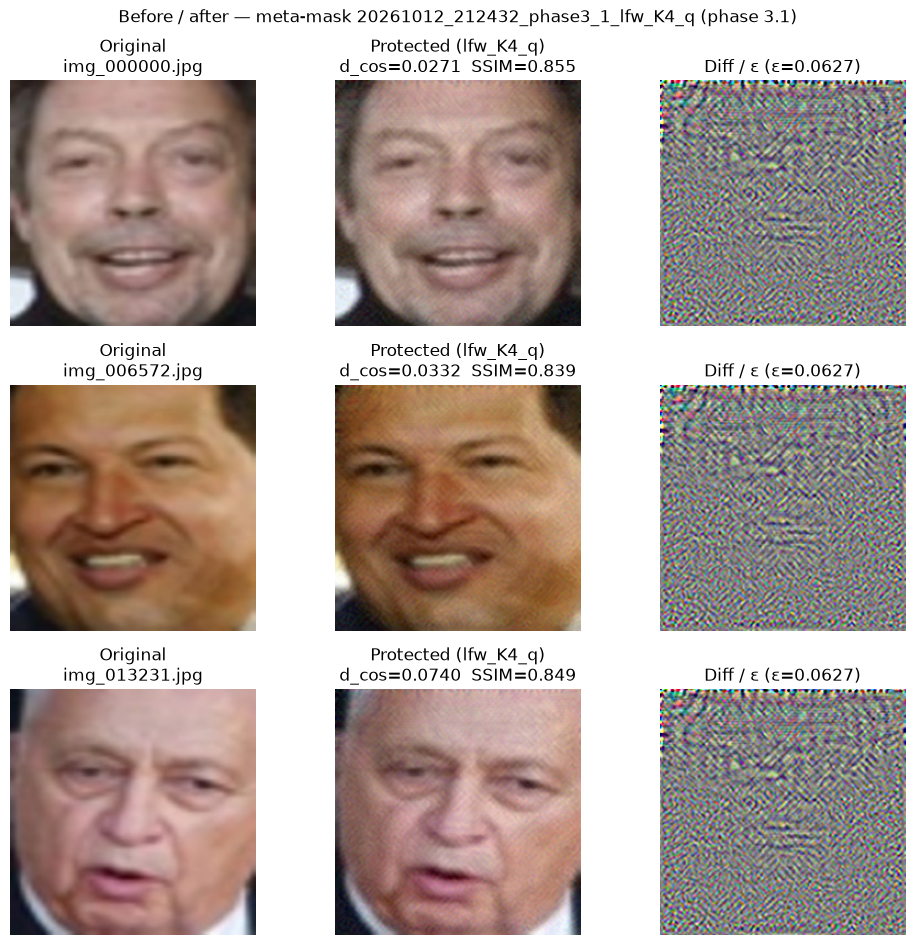

In [11]:
def to_np_img(t: torch.Tensor) -> np.ndarray:
    return t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(N_IMAGES, 3, figsize=(10, 3.2 * N_IMAGES))
if N_IMAGES == 1:
    axes = np.expand_dims(axes, 0)

for i in range(N_IMAGES):
    orig = to_np_img(imgs[i])
    prot = to_np_img(protected[i])
    # residual already L∞-bounded; amplify for display
    diff = np.clip((prot - orig) / (epsilon + 1e-8) * 0.5 + 0.5, 0, 1)

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Original\n{Path(paths[i]).name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(prot)
    axes[i, 1].set_title(
        f"Protected (lfw_K4_q)\ncos_sim={cos_sim[i].item():.4f}  SSIM={ssims[i]:.3f}"
    )
    axes[i, 1].axis("off")

    axes[i, 2].imshow(diff)
    axes[i, 2].set_title(f"Diff / ε (ε={epsilon:.4f})")
    axes[i, 2].axis("off")

fig.suptitle(f"Before / after — meta-mask {cfg.get('run_id')} (phase 3.1)", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Tabela resumo

In [12]:
rows = []
for i, p in enumerate(paths):
    rows.append({
        "image": Path(p).name,
        "cos_similarity": float(cos_sim[i]),  # lower = better de-ID
        "ssim": float(ssims[i]),
        "linf_pixel": float(residual[i].abs().max()),
        "l2_pixel": float((protected[i] - imgs[i]).pow(2).mean().sqrt()),
    })
df = pd.DataFrame(rows)
display(df)
print("mean cos_similarity (lower=better):", df["cos_similarity"].mean())
print("mean SSIM:", df["ssim"].mean(), "| target min_ssim:", min_ssim)

,image,cos_similarity,cos_distance,ssim,linf_pixel,l2_pixel
0,img_000000.jpg,0.972881,0.027119,0.855240,0.062745,0.018516
1,img_006572.jpg,0.966844,0.033156,0.839017,0.062745,0.018508
2,img_013231.jpg,0.926000,0.074000,0.849272,0.062745,0.018508


mean cos_distance: 0.0447585384051005
mean SSIM: 0.8478431502978007 | target min_ssim: 0.95


## 5. Avaliação em lote (~200 imagens)

Mesmo pipeline da secção 3 (máscara + L∞ + FR), mas em `N_EVAL` faces do split `faces_test` do LFW.

Reporta média / std / percentis de:
- **SSIM** (qualidade)
- **`cos_similarity`** (desidentificação; **menor = melhor**)
- **L∞** e **L2** do residual espacial

Evaluating 200/2029 test images from /mnt/databases/faces/lfw_frontal/faces_test
batch_size=16  fr=inception_facenet_vgg  epsilon=0.06275
  processed 16/200
  processed 32/200
  processed 48/200
  processed 64/200
  processed 80/200
  processed 96/200
  processed 112/200
  processed 128/200
  processed 144/200
  processed 160/200
  processed 176/200
  processed 192/200
  processed 200/200

=== Summary over 200 images ===


,mean,std,min,p25,median,p75,max
metric,,,,,,,
ssim,0.8554,0.0117,0.8264,0.8478,0.8562,0.8631,0.8830
cos_distance,0.0281,0.0167,0.0050,0.0156,0.0239,0.0363,0.1011
cos_similarity,0.9719,0.0167,0.8989,0.9637,0.9761,0.9844,0.9950
linf_pixel,0.0627,0.0000,0.0627,0.0627,0.0627,0.0627,0.0627
l2_pixel,0.0184,0.0001,0.0174,0.0184,0.0185,0.0185,0.0185



mean SSIM          : 0.8554  (target min_ssim=0.95)
mean cos_distance  : 0.0281
mean cos_similarity: 0.9719
frac SSIM >= min_ssim: 0.000
mean linf_pixel    : 0.06275  (budget=0.06275)


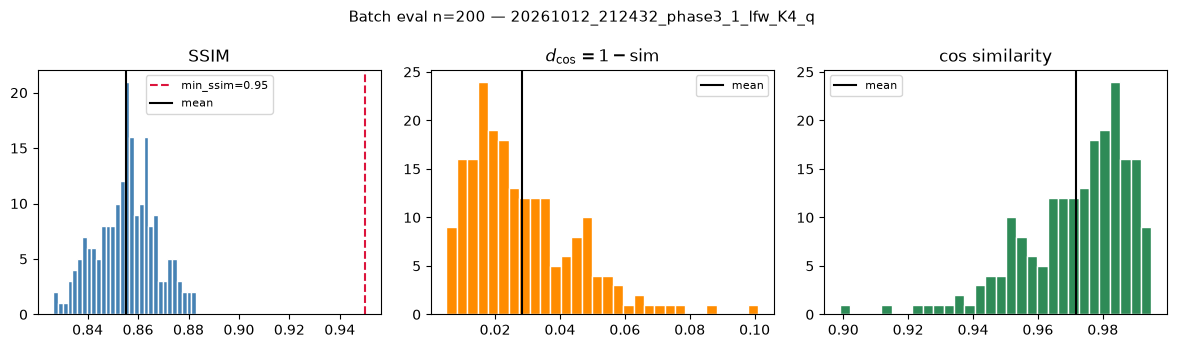


First 10 rows:


,image,cos_similarity,cos_distance,ssim,linf_pixel,l2_pixel
0,img_000000.jpg,0.972881,0.027119,0.855240,0.062745,0.018516
1,img_000059.jpg,0.972377,0.027623,0.853478,0.062745,0.018516
2,img_000102.jpg,0.974797,0.025203,0.849573,0.062745,0.018250
3,img_000157.jpg,0.979538,0.020462,0.848794,0.062745,0.018488
4,img_000248.jpg,0.958446,0.041554,0.838875,0.062745,0.018517
5,img_000304.jpg,0.988746,0.011254,0.863474,0.062745,0.018469
6,img_000373.jpg,0.988015,0.011985,0.864176,0.062745,0.018432
7,img_000428.jpg,0.986388,0.013612,0.841687,0.062745,0.018508
8,img_000483.jpg,0.967772,0.032228,0.836294,0.062745,0.018511
9,img_000538.jpg,0.954563,0.045437,0.835409,0.062745,0.018511


In [13]:
# Reuse FR from section 3 if already loaded; otherwise create it.
if "fr" not in globals():
    fr = FR(model_name=fr_name, device=DEVICE)
    fr.fr_model.model.eval()
    for p in fr.fr_model.model.parameters():
        p.requires_grad_(False)

split_dir_eval = resolve_split_dir("lfw_frontal", "test")
all_paths_eval = list_image_paths(split_dir_eval)
n_avail = len(all_paths_eval)
n_use = min(N_EVAL, n_avail)
# Evenly spaced sample so we cover the test set, not only the first N files.
eval_idxs = np.linspace(0, n_avail - 1, num=n_use, dtype=int)
eval_paths = [all_paths_eval[i] for i in eval_idxs]
print(f"Evaluating {n_use}/{n_avail} test images from {split_dir_eval}")
print(f"batch_size={EVAL_BATCH}  fr={fr_name}  epsilon={epsilon:.5f}")

rows_eval = []
with torch.no_grad():
    for start in range(0, n_use, EVAL_BATCH):
        batch_paths = eval_paths[start : start + EVAL_BATCH]
        batch = load_imgs(img_paths=batch_paths, img_sz=img_size, drange=1, device=DEVICE)
        recon = mask_mod(batch)
        prot, res = apply_linf_budget(recon, batch, epsilon)

        feat_o = F.normalize(fr(batch), p=2, dim=1)
        feat_p = F.normalize(fr(prot), p=2, dim=1)
        sim = (feat_o * feat_p).sum(dim=1)
        dist = 1.0 - sim

        for i, p in enumerate(batch_paths):
            ssim_i = float(
                calc_ssim(
                    prot[i : i + 1], batch[i : i + 1], data_range=1.0, size_average=True
                ).cpu()
            )
            rows_eval.append({
                "image": Path(p).name,
                "cos_similarity": float(sim[i].cpu()),  # lower = better de-ID
                "ssim": ssim_i,
                "linf_pixel": float(res[i].abs().max().cpu()),
                "l2_pixel": float((prot[i] - batch[i]).pow(2).mean().sqrt().cpu()),
            })
        print(f"  processed {min(start + EVAL_BATCH, n_use)}/{n_use}")

df_eval = pd.DataFrame(rows_eval)

def _stats(series: pd.Series) -> dict:
    return {
        "mean": float(series.mean()),
        "std": float(series.std(ddof=0)),
        "min": float(series.min()),
        "p25": float(series.quantile(0.25)),
        "median": float(series.median()),
        "p75": float(series.quantile(0.75)),
        "max": float(series.max()),
    }

metric_cols = ["ssim", "cos_similarity", "linf_pixel", "l2_pixel"]
summary_eval = pd.DataFrame({c: _stats(df_eval[c]) for c in metric_cols}).T
summary_eval.index.name = "metric"

print("\n=== Summary over", len(df_eval), "images ===")
print("(cos_similarity: lower = better de-identification)")
display(summary_eval.round(4))
print(f"\nmean SSIM          : {df_eval['ssim'].mean():.4f}  (target min_ssim={min_ssim})")
print(f"mean cos_similarity: {df_eval['cos_similarity'].mean():.4f}  (lower=better)")
print(f"frac SSIM >= min_ssim: {(df_eval['ssim'] >= min_ssim).mean():.3f}")
print(f"mean linf_pixel    : {df_eval['linf_pixel'].mean():.5f}  (budget={epsilon:.5f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df_eval["ssim"], bins=30, color="steelblue", edgecolor="white")
axes[0].axvline(min_ssim, color="crimson", ls="--", label=f"min_ssim={min_ssim}")
axes[0].axvline(df_eval["ssim"].mean(), color="black", ls="-", label="mean")
axes[0].set_title("SSIM")
axes[0].legend(fontsize=8)

axes[1].hist(df_eval["cos_similarity"], bins=30, color="seagreen", edgecolor="white")
axes[1].axvline(df_eval["cos_similarity"].mean(), color="black", ls="-", label="mean")
axes[1].set_title("cos_similarity (lower=better de-ID)")
axes[1].legend(fontsize=8)

fig.suptitle(f"Batch eval n={len(df_eval)} — {cfg.get('run_id')}", fontsize=11)
plt.tight_layout()
plt.show()

print("\nFirst 10 rows:")
display(df_eval.head(10))